# Topic 1: Correlation Matrix

## Step 1: Understand the Concept

A **Correlation Matrix** is a table that shows the correlation between multiple numerical variables in a dataset.

Correlation helps us understand the direction and strength of a linear relationship between two variables.

### Why Do We Use a Correlation Matrix?

- To identify strong and weak relationships between numerical features.
- To find positive and negative correlations.
- To understand patterns in the dataset.
- To identify potential multicollinearity between input features.
- To support feature selection in Machine Learning.

### Correlation Range

Correlation values range from -1 to +1.

- **+1:** Perfect positive correlation.
- **Near +1:** Strong positive correlation.
- **Near 0:** Weak or no linear correlation.
- **Near -1:** Strong negative correlation.
- **-1:** Perfect negative correlation.

A correlation matrix compares multiple numerical variables in a single table.

## Step 2: Demonstrate the Concept

### Simple Example

Imagine a shop records the quantity of products sold and their unit prices.

| Quantity | Price |
|---:|---:|
| 2 | 10 |
| 4 | 20 |
| 6 | 30 |

In this simplified example, Quantity and Price increase together, showing a positive relationship.

### Real-World Example

A retail business can analyze product quantities, unit prices, and total sales amounts to discover relationships in its transaction data.

### Business Example

A business can use a correlation matrix to explore whether certain numerical variables move together and identify patterns that may support business decisions.

### AI/ML Use Case

In Machine Learning, a correlation matrix helps identify highly correlated input features. Highly correlated features may create multicollinearity in some models.

### Importance

A correlation matrix summarizes several pairwise relationships in one table, making numerical patterns easier to compare.

**Variable Scope Rule:** Use meaningful numerical features for correlation analysis. Numeric identifiers such as customer IDs or product codes should not automatically be treated as meaningful numerical features.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "online_retail_II.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# Step 3: Implement the Concept

# Select meaningful numerical columns
correlation_data = df[["Quantity", "Price"]].copy()

# Convert columns to numeric values
correlation_data["Quantity"] = pd.to_numeric(
    correlation_data["Quantity"], errors="coerce"
)
correlation_data["Price"] = pd.to_numeric(
    correlation_data["Price"], errors="coerce"
)

# Remove missing and infinite values
correlation_data = correlation_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Create a derived feature for transaction line amount
correlation_data["TotalAmount"] = (
    correlation_data["Quantity"] * correlation_data["Price"]
)

# Calculate the correlation matrix
correlation_matrix = correlation_data.corr()

# Display the correlation matrix
print("Correlation Matrix:")
display(correlation_matrix.round(3))

Correlation Matrix:


,Quantity,Price,TotalAmount
Quantity,1.000,-0.002,0.156
Price,-0.002,1.000,0.453
TotalAmount,0.156,0.453,1.000


## Code Explanation

### 1. Select Numerical Columns

`df[["Quantity", "Price"]]` selects the two numerical columns needed for this analysis.

### 2. Convert Values to Numeric

`pd.to_numeric()` converts column values into numeric data. Invalid values are converted to missing values using `errors="coerce"`.

### 3. Clean the Data

`replace()` changes infinite values to missing values, and `dropna()` removes rows containing missing values in the selected columns.

### 4. Create TotalAmount

`TotalAmount` is calculated by multiplying Quantity by Price.

**Formula:**

Total Amount = Quantity × Unit Price

This represents the transaction line amount before considering discounts, taxes, or other adjustments.

### 5. Calculate the Correlation Matrix

`correlation_data.corr()` calculates the pairwise Pearson correlation coefficients for the numerical columns.

`round(3)` displays the values rounded to three decimal places.

### How to Interpret the Output

- A positive value indicates a positive linear relationship.
- A negative value indicates a negative linear relationship.
- A value close to zero indicates a weak linear relationship.
- A value close to +1 or -1 indicates a strong linear relationship.

The diagonal values will be 1.0 because each variable is perfectly correlated with itself.

### Where It Is Used in AI/ML or Data Analytics

Correlation matrices help analysts explore numerical feature relationships, identify potentially redundant features, and investigate possible multicollinearity before model training.

**Observation:** After running the code, record which feature pairs show strong positive, strong negative, or weak correlations. Base your findings on the actual output rather than assumptions.

# Topic 2: Heatmap

## Step 1: Understand the Concept

A **Heatmap** is a data visualization technique that represents numerical values using colors.

In Multivariate Analysis, a heatmap is commonly used to visualize a correlation matrix. It helps us identify positive, negative, strong, and weak relationships between numerical features.

### Why Do We Use a Heatmap?

- To visualize correlation values clearly.
- To compare relationships between multiple numerical features.
- To identify strong and weak correlations.
- To investigate potential multicollinearity.
- To make patterns in a correlation matrix easier to understand.

A heatmap provides a visual summary of numerical relationships, while the correlation values provide the exact measurements.

## Step 2: Demonstrate the Concept

### Simple Example

Imagine a retail dataset containing Quantity, Price, and TotalAmount.

A heatmap can display the correlation between these three numerical features using different colors.

### Real-World Example

A retail analyst can use a heatmap to explore how product quantity, unit price, and transaction amount are related.

### Business Example

A business can use a heatmap to identify numerical features that move together and investigate whether some features provide similar information.

### AI/ML Use Case

During feature analysis, a heatmap helps identify highly correlated input features. This can help investigate potential multicollinearity before model training.

### Importance

A heatmap makes it easier to compare several correlation values at once. However, correlation does not prove causation, and a strong correlation does not automatically confirm multicollinearity.

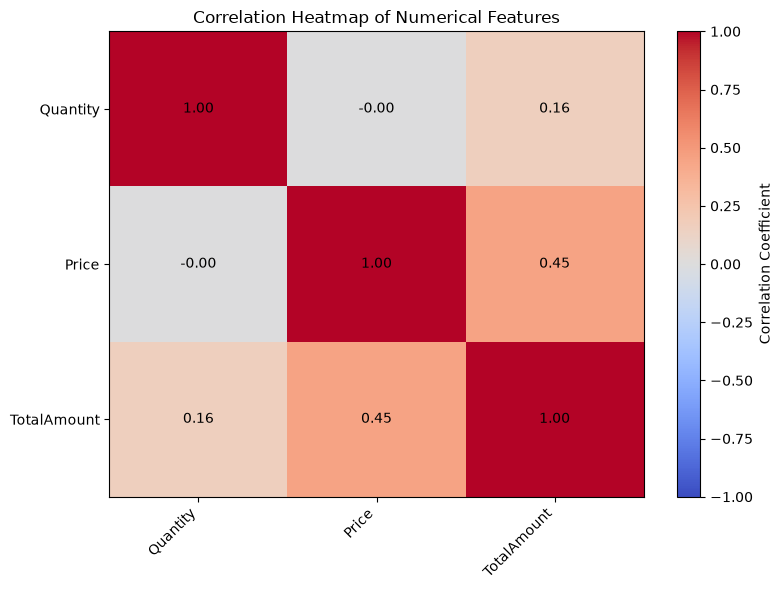

In [4]:
# Step 3: Implement the Concept

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

# Display correlation values inside the heatmap
for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[i, j]
        plt.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Set the Figure Size

`plt.figure(figsize=(8, 6))` creates a figure with a suitable size for the heatmap.

### 2. Display the Heatmap

`plt.imshow()` displays the correlation matrix as a color-coded grid.

- `cmap="coolwarm"` selects a color map.
- `vmin=-1` sets the minimum correlation value.
- `vmax=1` sets the maximum correlation value.

### 3. Add Labels

`plt.xticks()` and `plt.yticks()` display feature names on the horizontal and vertical axes.

### 4. Add the Color Scale

`plt.colorbar()` displays a scale showing how colors correspond to correlation values.

### 5. Display the Values

`plt.text()` writes each correlation value inside its corresponding cell, rounded to two decimal places.

### Where It Is Used in AI/ML or Data Analytics

Heatmaps help data analysts explore numerical feature relationships, identify possible redundant features, and investigate potential multicollinearity during exploratory data analysis.

### Observation

After running the heatmap, record:

- Which feature pairs have strong positive correlations?
- Which feature pairs have negative correlations?
- Which feature pairs have weak correlations?
- Are any features potentially redundant?

Write your observations based on the actual correlation values shown in your heatmap.

# Topic 3: Pair Plot

## Step 1: Understand the Concept

A **Pair Plot** is a visualization that displays pairwise relationships between multiple numerical features in a dataset.

It usually shows scatter plots for pairs of different features and distribution plots along the diagonal.

### Why Do We Use a Pair Plot?

- To compare relationships between multiple numerical features.
- To identify positive and negative patterns.
- To observe possible clusters and unusual data points.
- To understand the individual distribution of each feature.
- To explore relationships before selecting features for Machine Learning.

A pair plot helps us examine several numerical relationships in a single figure.

## Step 2: Demonstrate the Concept

### Simple Example

Consider three numerical features: Quantity, Price, and TotalAmount.

A pair plot compares each feature against the others and displays the distribution of each feature along the diagonal.

### Real-World Example

A retail analyst can compare product quantities, unit prices, and transaction amounts to identify patterns in purchasing data.

### Business Example

A business can investigate whether transactions involving larger quantities tend to have larger transaction amounts.

### AI/ML Use Case

Pair plots help analysts explore feature relationships, potential clusters, and unusual observations before training a Machine Learning model.

### Importance

Pair plots provide a quick visual overview of multiple numerical features. Large datasets can make pair plots slow and difficult to read, so a representative sample is often useful.

In [6]:
%pip install seaborn

   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/294.9 kB 220.2 kB/s eta 0:00:02
   -------- ------------------------------ 61.4/294.9 kB 297.7 kB/s eta 0:00:01
   --------------- ---------------------- 122.9/294.9 kB 516.7 kB/s eta 0:00:01
   ---------------------- --------------- 174.1/294.9 kB 618.3 kB/s eta 0:00:01
   ------------------------------------ - 286.7/294.9 kB 930.9 kB/s eta 0:00:01
   -------------------------------------- 294.9/294.9 kB 867.9 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


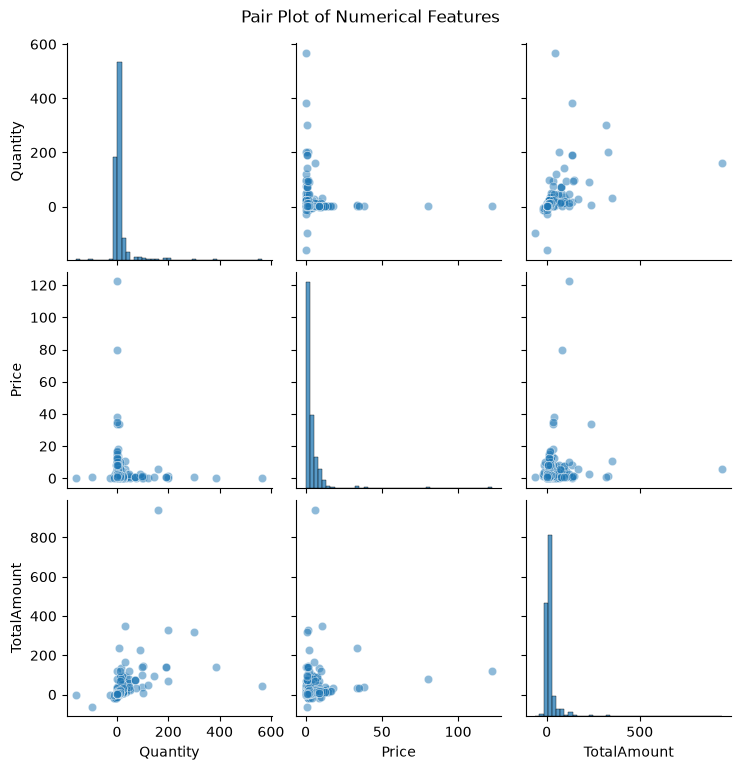

In [7]:
# Step 3: Implement the Concept

import seaborn as sns

# Select numerical features for pair plot
pair_data = correlation_data[
    ["Quantity", "Price", "TotalAmount"]
].copy()

# Use a sample if the dataset is large
if len(pair_data) > 500:
    pair_data = pair_data.sample(
        n=500,
        random_state=42
    )

# Create the pair plot
sns.pairplot(
    pair_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.5}
)

plt.suptitle(
    "Pair Plot of Numerical Features",
    y=1.02
)

plt.show()

## Code Explanation

### 1. Import Seaborn

`import seaborn as sns` imports Seaborn, a Python library used for statistical data visualization.

### 2. Select Numerical Features

The code selects Quantity, Price, and TotalAmount from `correlation_data`.

### 3. Create a Sample

`sample(n=500, random_state=42)` selects 500 rows when more than 500 rows are available. The fixed random state makes the sample reproducible.

### 4. Create the Pair Plot

`sns.pairplot()` creates scatter plots for feature pairs and histograms along the diagonal.

- `diag_kind="hist"` displays histograms on the diagonal.
- `alpha=0.5` makes overlapping scatter points easier to distinguish.

### Where It Is Used in AI/ML or Data Analytics

Pair plots help explore relationships between numerical features, detect potential clusters, and identify unusual observations during Exploratory Data Analysis.

### Observation

After running the plot, record:

- Which feature pairs show a visible relationship?
- Are the relationships positive, negative, or unclear?
- Do you notice clusters or unusual observations?
- How do the individual feature distributions look?

Base your observations on the actual plot. A visible pattern does not necessarily indicate causation.

# Topic 4: Multiple Feature Relationships

## Step 1: Understand the Concept

Multiple Feature Relationships analysis examines how three or more features relate to one another within a dataset.

Instead of studying only one pair of variables, this analysis considers several features together to identify patterns and understand how they may be connected.

### Why Do We Analyze Multiple Feature Relationships?

- To understand patterns involving several numerical features.
- To identify relationships that may not be obvious when examining one feature at a time.
- To explore how business variables are connected.
- To support feature selection and data preparation.
- To improve understanding of a dataset before Machine Learning model development.

In this notebook, Quantity, Price, and TotalAmount will be analyzed together.

## Step 2: Demonstrate the Concept

### Simple Example

Consider a retail transaction containing Quantity, Price, and TotalAmount.

| Quantity | Price | TotalAmount |
|---:|---:|---:|
| 2 | 10 | 20 |
| 3 | 15 | 45 |
| 4 | 20 | 80 |

TotalAmount is calculated by multiplying Quantity by Price.

### Real-World Example

A retail analyst can study product quantity, unit price, and transaction amount together to understand transaction patterns.

### Business Example

A business can investigate whether larger quantities are associated with higher transaction amounts and whether unit price changes the pattern.

### AI/ML Use Case

Analyzing multiple features can help identify useful input variables, redundant features, and patterns that may support predictive modeling.

### Importance

Studying multiple features together provides a broader view of the dataset. However, observed relationships should be validated using actual data and appropriate statistical methods.

Summary of Multiple Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Quantity,525461.0,10.34,107.42,-9600.00,1.00,3.00,10.00,19152.00
Price,525461.0,4.69,146.13,-53594.36,1.25,2.10,4.21,25111.09
TotalAmount,525461.0,18.15,160.33,-53594.36,3.75,9.95,17.70,25111.09


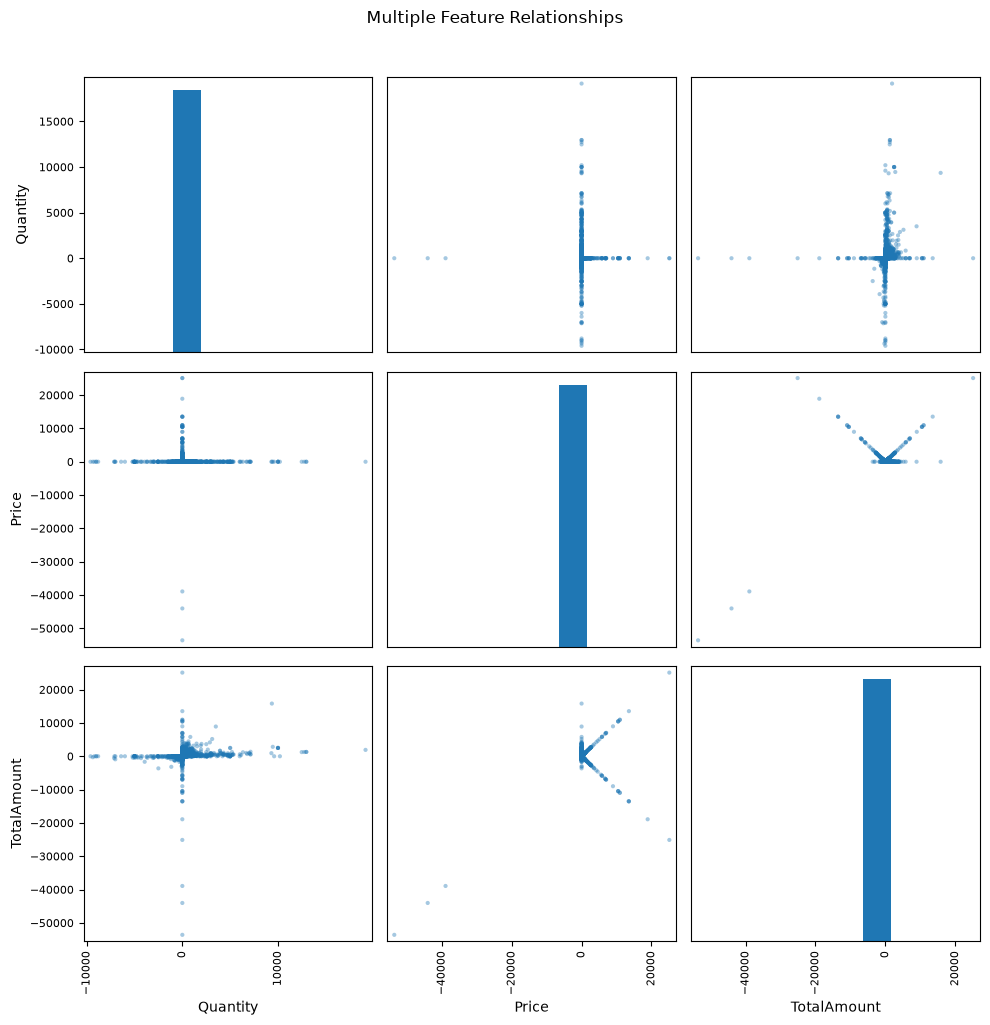

Correlation Matrix:


,Quantity,Price,TotalAmount
Quantity,1.000,-0.002,0.156
Price,-0.002,1.000,0.453
TotalAmount,0.156,0.453,1.000


In [8]:
# Step 3: Implement the Concept

# Select multiple numerical features
multi_feature_data = correlation_data[
    ["Quantity", "Price", "TotalAmount"]
].copy()

# Calculate descriptive statistics
feature_summary = multi_feature_data.describe().T

print("Summary of Multiple Numerical Features:")
display(feature_summary.round(2))

# Visualize relationships among all three features
axes = pd.plotting.scatter_matrix(
    multi_feature_data,
    figsize=(10, 10),
    diagonal="hist",
    alpha=0.4
)

plt.suptitle(
    "Multiple Feature Relationships",
    y=1.02
)

plt.tight_layout()
plt.show()

# Display correlations for comparison
print("Correlation Matrix:")
display(multi_feature_data.corr().round(3))

## Code Explanation

### 1. Select Multiple Features

The code selects Quantity, Price, and TotalAmount for joint analysis.

### 2. Calculate Descriptive Statistics

`describe()` calculates statistics such as count, mean, standard deviation, minimum, maximum, and quartiles.

`.T` transposes the summary so that each feature appears as a row.

### 3. Create a Scatter Matrix

`pd.plotting.scatter_matrix()` creates scatter plots for pairs of numerical features and histograms along the diagonal.

This visualization helps compare several feature relationships in one figure.

### 4. Display the Correlation Matrix

`multi_feature_data.corr()` calculates pairwise Pearson correlation coefficients for the selected numerical features.

### Where It Is Used in AI/ML or Data Analytics

Multiple feature analysis helps data analysts understand feature distributions and relationships, investigate redundant variables, and prepare features for Machine Learning.

### Observation

After running the code, record:

- Which feature pairs show visible patterns?
- Which features have strong or weak correlations?
- Are any features mathematically dependent on other features?
- What interesting relationships can you observe across the three features?

Use the actual statistics, plots, and correlation values to write your findings.

# Topic 5: Feature Interactions

## Step 1: Understand the Concept

A **Feature Interaction** occurs when the relationship between one feature and an outcome depends on the value of another feature.

Feature interactions help us understand how multiple variables work together instead of examining each variable independently.

### Why Do We Analyze Feature Interactions?

- To understand combined effects of multiple features.
- To identify patterns that may be missed by studying features separately.
- To explore business relationships between variables.
- To support feature engineering in Machine Learning.
- To investigate whether combinations of features improve predictive performance.

In this retail dataset, Quantity and Price can be examined together in relation to TotalAmount.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following transactions:

| Quantity | Price | TotalAmount |
|---:|---:|---:|
| 2 | 10 | 20 |
| 2 | 20 | 40 |
| 4 | 10 | 40 |
| 4 | 20 | 80 |

TotalAmount is calculated using:

**TotalAmount = Quantity × Price**

### Real-World Example

In a retail business, the transaction amount depends on both the number of products purchased and the unit price of each product.

### Business Example

A business can compare transaction amounts across different quantity and price combinations to understand sales patterns.

### AI/ML Use Case

Feature interactions can be represented through feature engineering, such as multiplying two input features. These additional features may help some Machine Learning models capture relationships that they would otherwise miss.

### Importance

Feature interaction analysis helps explore how variables work together. A mathematically created feature does not automatically prove a causal relationship or guarantee better model performance.

Feature Interaction Summary:


,Price,TotalAmount
QuantityGroup,,
1,7.73,7.73
2-5,4.02,11.03
6-10,2.62,18.84
Above 10,1.54,46.16


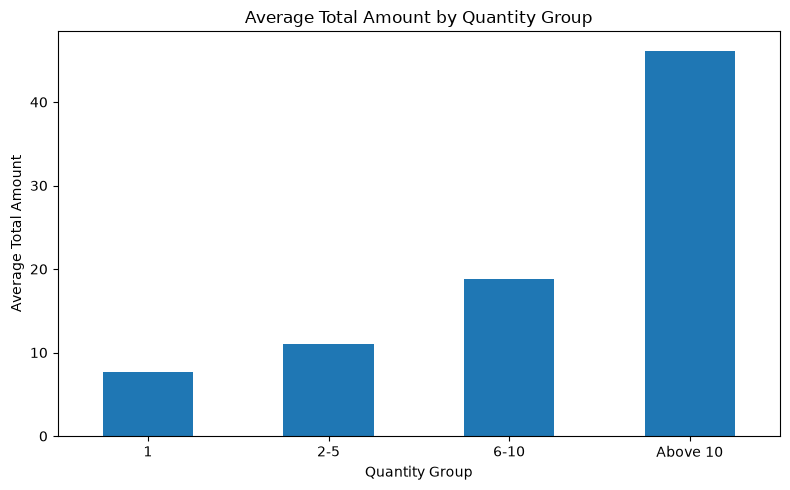

In [9]:
# Step 3: Implement the Concept

# Create a working copy
interaction_data = correlation_data[
    ["Quantity", "Price", "TotalAmount"]
].copy()

# Keep positive quantities and non-negative prices
interaction_data = interaction_data[
    (interaction_data["Quantity"] > 0) &
    (interaction_data["Price"] >= 0)
].copy()

# Create quantity groups
interaction_data["QuantityGroup"] = pd.cut(
    interaction_data["Quantity"],
    bins=[0, 1, 5, 10, np.inf],
    labels=["1", "2-5", "6-10", "Above 10"],
    include_lowest=True
)

# Compare average price and transaction amount by quantity group
interaction_summary = interaction_data.groupby(
    "QuantityGroup",
    observed=False
)[["Price", "TotalAmount"]].mean()

print("Feature Interaction Summary:")
display(interaction_summary.round(2))

# Visualize average transaction amount by quantity group
interaction_summary["TotalAmount"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Total Amount by Quantity Group")
plt.xlabel("Quantity Group")
plt.ylabel("Average Total Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select Features

The code selects Quantity, Price, and TotalAmount from the existing correlation data.

### 2. Filter Values

Only positive quantities and non-negative prices are retained for this analysis.

### 3. Create Quantity Groups

`pd.cut()` groups quantity values into four categories: 1, 2–5, 6–10, and above 10.

This makes it easier to compare transaction patterns across quantity ranges.

### 4. Calculate Group Averages

`groupby()` groups the records by QuantityGroup, and `mean()` calculates the average Price and TotalAmount for each group.

### 5. Create the Bar Chart

The bar chart displays the average TotalAmount for each quantity group, making group-level differences easier to compare.

### Where It Is Used in AI/ML or Data Analytics

Feature interaction analysis helps explore combinations of variables and supports feature engineering. The usefulness of interaction features should be tested during model evaluation.

### Observation

After running the code, record:

- Which quantity group has the highest average TotalAmount?
- How does average Price differ across the groups?
- Does average TotalAmount change across quantity groups?
- What patterns can you observe in this dataset?

Write your findings using the actual output. Group averages alone cannot establish that Quantity causes changes in Price or TotalAmount.

# Topic 6: Numerical Feature Relationships

## Step 1: Understand the Concept

Numerical Feature Relationships analysis examines how numerical variables are associated with one another.

It uses statistical measurements and visualizations to understand the direction, strength, and pattern of relationships between numerical features.

### Why Do We Analyze Numerical Feature Relationships?

- To identify positive and negative relationships.
- To measure the strength of linear relationships.
- To identify weak or strong correlations.
- To investigate potential multicollinearity.
- To support feature selection and Machine Learning preparation.

Correlation coefficients and scatter plots are commonly used to examine numerical feature relationships.

## Step 2: Demonstrate the Concept

### Simple Example

Consider two numerical features, Quantity and Price.

When both values increase together, they may show a positive relationship. When one tends to decrease as the other increases, they may show a negative relationship.

When the points do not follow a clear linear pattern, the linear correlation may be weak.

### Real-World Example

A retail analyst can study the relationship between the number of products purchased and their unit prices.

### Business Example

A business can analyze numerical transaction features to understand purchasing patterns and identify relationships worth investigating.

### AI/ML Use Case

Numerical feature relationship analysis supports exploratory data analysis, feature selection, and the investigation of potential multicollinearity before model training.

### Importance

Correlation coefficients measure linear association. A low correlation does not rule out a nonlinear relationship, so visualizations are useful alongside statistical measurements.

Pearson Correlation Matrix:


,Quantity,Price,TotalAmount
Quantity,1.000,-0.002,0.156
Price,-0.002,1.000,0.453
TotalAmount,0.156,0.453,1.000


Spearman Correlation Matrix:


,Quantity,Price,TotalAmount
Quantity,1.000,-0.413,0.701
Price,-0.413,1.000,0.280
TotalAmount,0.701,0.280,1.000


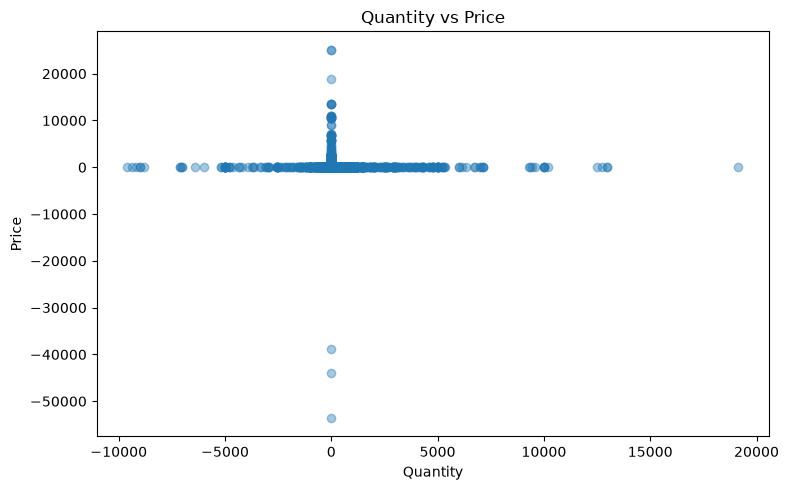

In [10]:
# Step 3: Implement the Concept

# Select numerical features
numerical_features = correlation_data[
    ["Quantity", "Price", "TotalAmount"]
].copy()

# Calculate Pearson correlation
pearson_corr = numerical_features.corr(
    method="pearson"
)

print("Pearson Correlation Matrix:")
display(pearson_corr.round(3))

# Calculate Spearman correlation
spearman_corr = numerical_features.corr(
    method="spearman"
)

print("Spearman Correlation Matrix:")
display(spearman_corr.round(3))

# Visualize Quantity vs Price
plt.figure(figsize=(8, 5))

plt.scatter(
    numerical_features["Quantity"],
    numerical_features["Price"],
    alpha=0.4
)

plt.title("Quantity vs Price")
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select Numerical Features

The code selects Quantity, Price, and TotalAmount for numerical relationship analysis.

### 2. Calculate Pearson Correlation

`corr(method="pearson")` measures the strength and direction of linear relationships between numerical variables.

### 3. Calculate Spearman Correlation

`corr(method="spearman")` measures the strength and direction of monotonic relationships using ranked values. It can help identify patterns that Pearson correlation may not describe well.

### 4. Create a Scatter Plot

`plt.scatter()` displays Quantity on the horizontal axis and Price on the vertical axis. The distribution of points helps us inspect the relationship visually.

### Where It Is Used in AI/ML or Data Analytics

Pearson and Spearman correlations help analysts investigate numerical feature relationships, identify patterns, and explore potentially redundant input features.

### Observation

After running the code, record:

- Which feature pairs have strong positive correlations?
- Which feature pairs have negative correlations?
- Which relationships appear weak?
- Are Pearson and Spearman correlation values different?
- Does the scatter plot support the observed correlation?

Use your actual output to identify the relationships. Correlation alone does not prove causation or confirm multicollinearity.